In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import plot_tree
from sklearn.metrics import f1_score,precision_score,recall_score,classification_report,confusion_matrix,accuracy_score


data=load_breast_cancer()
X=data.data
y=data.target

X=pd.DataFrame(data.data,columns=data.feature_names)
print(X.head())
print(X.shape)

print(data.target_names)


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [47]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("TRAIN DATA:",X_train.shape)
print("TESTING DATA:",X_test.shape)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        max_features="log2",
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    ))
])

pipeline.fit(X_train,y_train)

TRAIN DATA: (455, 30)
TESTING DATA: (114, 30)


,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2


In [50]:
y_train_pred=pipeline.predict(X_train)
y_test_pred=pipeline.predict(X_test)
print("THE ACTUAL VALUES:",y_train_pred)
print("THE TESTING VALUES:",y_test_pred)

THE ACTUAL VALUES: [1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 0 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0 0 0
 1 0 1 1 1 0 1 0 1 1 0 1 0 0 0 1 1 1 1 1 0 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 0
 1 1 1 1 1 0 0 0 0 0 1 1 0 0 1 0 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1
 0 0 0 1 1 1 0 0 1 1 1 1 0 1 0 0 1 0 1 1 1 0 1 1 0 1 0 1 1 0 1 1 0 1 1 1 0
 1 0 1 1 1 0 0 1 1 0 1 1 0 1 1 1 0 1 0 0 0 0 1 0 0 1 0 1 1 1 1 1 1 1 1 1 1
 0 1 1 0 1 1 1 1 1 0 1 1 0 0 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1
 1 1 1 0 1 0 0 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 1 1 1 0 0 1 1 0 0 1 1 1 0
 0 0 1 1 1 0 1 1 1 1 1 1 0 0 1 0 1 0 0 0 1 1 1 0 1 0 0 1 0 1 1 1 0 1 1 1 0
 0 0 0 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0 1 1 1 0 1 0 0 1 1 1 1 1 1 1 0
 1 0 1 1 1 1 0 1 1 0 0 1 1 1 0 1 1 0 1 0 0 1 1 0 0 0 1 0 1 1 1 1 0 0 1 1 1
 0 1 0 1 0 0 1 1 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 1 0 1 1 0 0 1 1 1 1 0 1 0 1
 1 1 0 1 1 1 0 1 0 0 0 1 1 1 1 0 0 0 1 0 1 1 1 0 0 0 1 0 1 1 1 1 0 0 0 1 1
 1 1 0 1 0 0 0 0 0 0 1]
THE TESTING VALUES: [0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 1 1 

In [48]:
accuracy = accuracy_score(y_train, y_train_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
confusion=confusion_matrix(y_test,y_test_pred)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("CONFUSION_MATRIX:",confusion)

print(classification_report(y_test,y_test_pred,target_names=data.target_names))

Accuracy: 0.9934065934065934
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1 Score: 0.9655172413793104
CONFUSION_MATRIX: [[39  3]
 [ 2 70]]
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



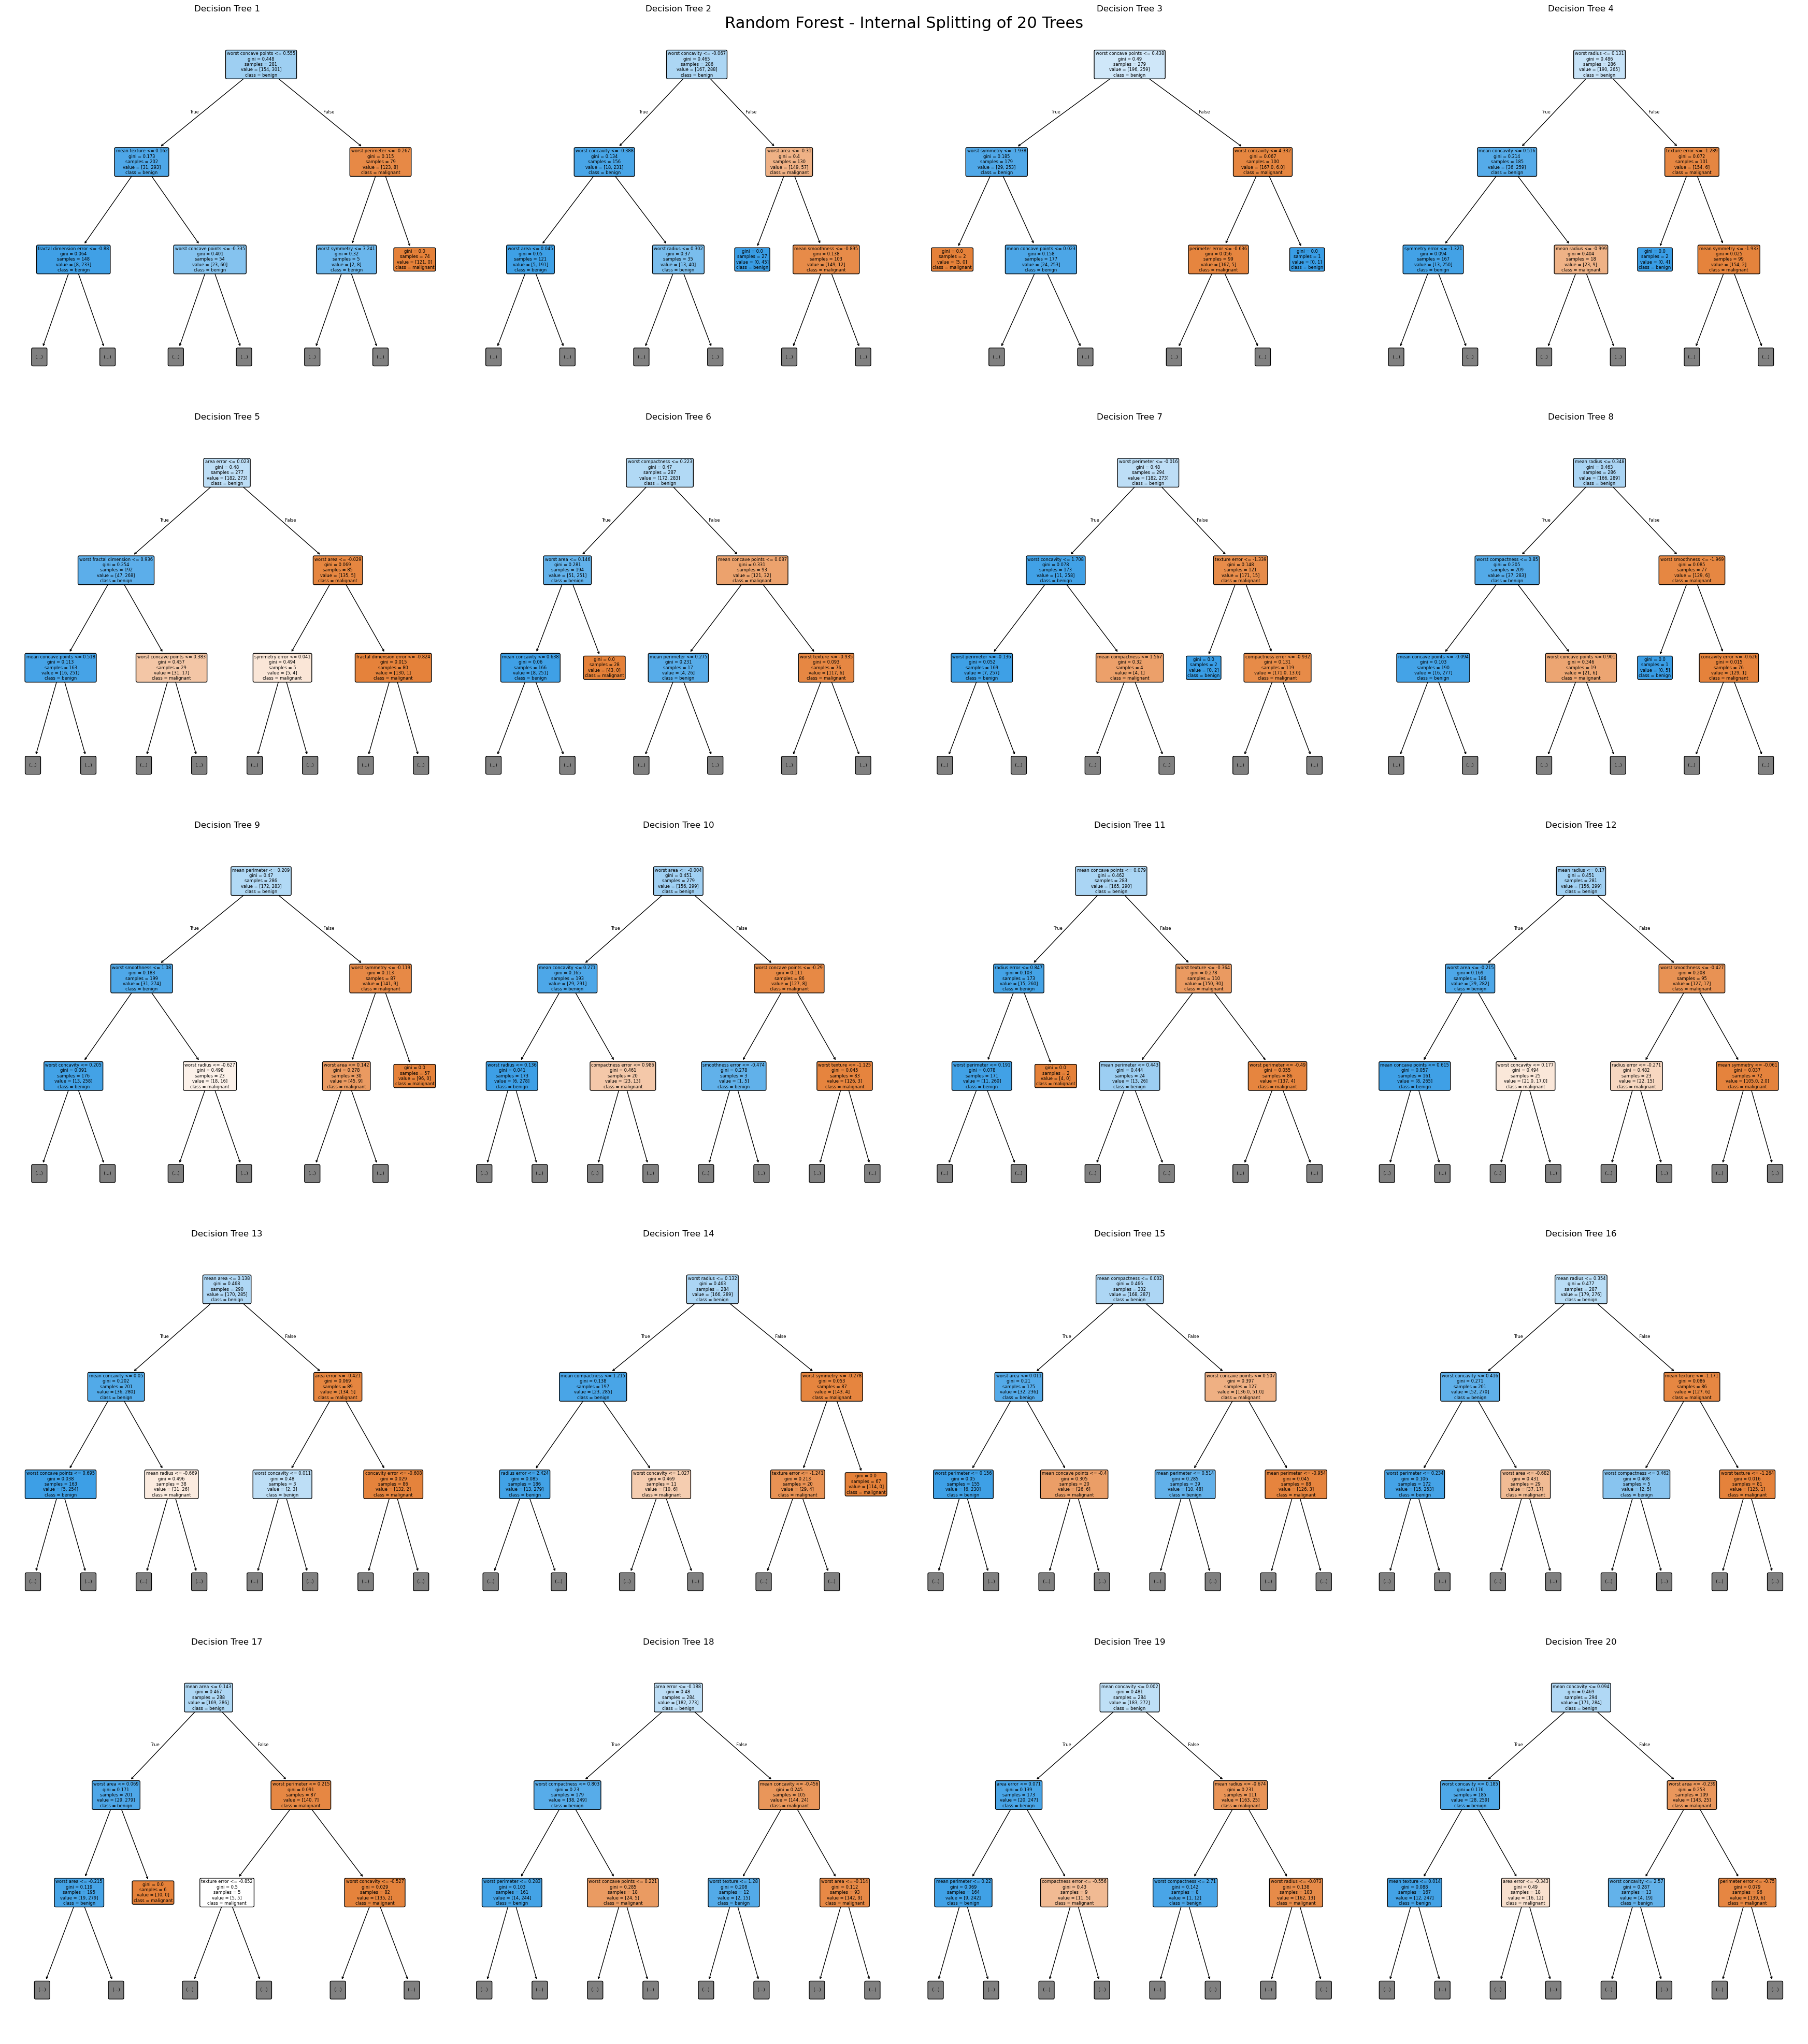

In [51]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract trained Random Forest
rf_model = pipeline.named_steps["model"]

# Number of trees to visualize
n_trees = 20

# Create 5 rows and 4 columns
fig, axes = plt.subplots(
    nrows=5,
    ncols=4,
    figsize=(35, 40)
)

axes = axes.flatten()
# Loop through first 20 trees
for i in range(n_trees):
    plot_tree(
        rf_model.estimators_[i],

        feature_names=data.feature_names,

        class_names=data.target_names,

        filled=True,

        rounded=True,

        max_depth=2,

        fontsize=6,

        ax=axes[i]
    )
    axes[i].set_title(
        f"Decision Tree {i+1}",
        fontsize=12
    )
plt.suptitle(
    "Random Forest - Internal Splitting of 20 Trees",
    fontsize=22
)
plt.tight_layout()
plt.show()